# E-commerce Sales Analysis
**Dataset:** 10,000 synthetic e-commerce orders (practice dataset)  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Goal:** Clean the data, find what drives revenue and returns, and turn charts into business insights.

> Google Colab: upload `ecommerce_orders_10k.csv` from the left Files panel first.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("ecommerce_orders_10k.csv")
df.head()

,order_id,customer_id,order_date,customer_age,gender,city,state,category,unit_price,quantity,discount_pct,order_amount,payment_method,is_prime_member,delivery_days,returned,rating
0,ORD106496,CUST4244,2025-10-14,32.0,Male,Bengaluru,Karnataka,Sports,5004.0,2,5,9507.60,UPI,No,2,No,5.0
1,ORD100631,CUST4483,2025-04-30,30.0,Male,Kolkata,West Bengal,Beauty,899.0,2,10,1618.20,Wallet,No,4,No,4.0
2,ORD108984,CUST2859,2025-03-19,30.0,Female,Delhi,Delhi,Books,239.0,3,0,717.00,Credit Card,No,9,No,3.0
3,ORD100948,CUST4573,2025-12-12,46.0,Male,Mumbai,Maharashtra,Electronics,3072.0,1,0,3072.00,UPI,No,4,No,4.0
4,ORD109252,CUST1711,2025-04-12,35.0,Male,Hyderabad,Telangana,Books,397.0,1,5,377.15,Credit Card,No,8,No,4.0


## 1. First look at the data

In [2]:
print(df.shape)
df.info()
print(df.isna().sum())
df.describe()

(10060, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10060 entries, 0 to 10059
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         10060 non-null  object 
 1   customer_id      10060 non-null  object 
 2   order_date       10060 non-null  object 
 3   customer_age     9757 non-null   float64
 4   gender           10060 non-null  object 
 5   city             10060 non-null  object 
 6   state            10060 non-null  object 
 7   category         10060 non-null  object 
 8   unit_price       10060 non-null  float64
 9   quantity         10060 non-null  int64  
 10  discount_pct     10060 non-null  int64  
 11  order_amount     10060 non-null  float64
 12  payment_method   9939 non-null   object 
 13  is_prime_member  10060 non-null  object 
 14  delivery_days    10060 non-null  int64  
 15  returned         10060 non-null  object 
 16  rating           9605 non-null   float64
dtype

,customer_age,unit_price,quantity,discount_pct,order_amount,delivery_days,rating
count,9757.000000,10060.000000,10060.000000,10060.000000,10060.000000,10060.000000,9605.000000
mean,31.400328,3881.824453,1.649105,10.602883,5826.319135,4.230020,4.103800
std,9.163129,8267.197774,1.010598,10.559780,15667.610408,1.772803,0.800582
min,18.000000,50.000000,1.000000,0.000000,32.400000,1.000000,1.000000
25%,25.000000,437.750000,1.000000,0.000000,526.300000,3.000000,4.000000
50%,31.000000,1091.000000,1.000000,10.000000,1405.700000,4.000000,4.000000
75%,37.000000,3121.000000,2.000000,15.000000,4140.400000,5.000000,5.000000
max,150.000000,59870.000000,5.000000,40.000000,290650.000000,11.000000,5.000000


## 2. Data cleaning
Order matters: fix the problems first, *then* fill the nulls.
1. Remove duplicates  2. Fix city names  3. Invalid ages -> NaN  4. Fill nulls  5. Remove impossible orders  6. Convert dates

In [3]:
# 1. duplicates
df = df.drop_duplicates()

# 2. messy city names ("mumbai ", "BENGALURU")
df["city"] = df["city"].str.strip().str.title()
print("cities:", df["city"].nunique())

# 3. impossible ages -> NaN
df["customer_age"] = pd.to_numeric(df["customer_age"], errors="coerce")
df.loc[df["customer_age"] > 100, "customer_age"] = np.nan

# 4. fill nulls
df["customer_age"] = df["customer_age"].fillna(df["customer_age"].median())  # median: robust to outliers
df["payment_method"] = df["payment_method"].fillna("Unknown")                  # 'Unknown' keeps the row
# rating left as NaN on purpose: we do not guess customer opinions

# 5. order_amount can never exceed unit_price * quantity (discount only reduces it)
gross = df["unit_price"] * df["quantity"]
print("invalid orders removed:", (df["order_amount"] > gross + 1).sum())
df = df[df["order_amount"] <= gross + 1]

# 6. dates and new columns
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.month
df["weekday"] = df["order_date"].dt.day_name()
df["is_returned"] = (df["returned"] == "Yes").astype(int)

print(df.shape)
print(df.isna().sum())

cities: 10
invalid orders removed: 15
(9985, 20)
order_id             0
customer_id          0
order_date           0
customer_age         0
gender               0
city                 0
state                0
category             0
unit_price           0
quantity             0
discount_pct         0
order_amount         0
payment_method       0
is_prime_member      0
delivery_days        0
returned             0
rating             450
month                0
weekday              0
is_returned          0
dtype: int64


## 3. Exploratory analysis

In [4]:
cat = df.groupby("category")["order_amount"].agg(["sum", "count", "mean"]).sort_values("sum", ascending=False)
cat["share_%"] = (cat["sum"] / cat["sum"].sum() * 100).round(1)
cat

,sum,count,mean,share_%
category,,,,
Electronics,37828593.45,1831,20660.072884,65.7
Home & Kitchen,7968953.15,1561,5105.030846,13.8
Fashion,5711930.10,2345,2435.791087,9.9
Sports,2929453.40,836,3504.130861,5.1
Beauty,1762113.30,1244,1416.489791,3.1
Grocery,728345.20,1198,607.967613,1.3
Books,621354.35,970,640.571495,1.1


In [5]:
city = df.groupby("city")["order_amount"].agg(["sum", "count", "mean"]).sort_values("sum", ascending=False)
city

,sum,count,mean
city,,,
Delhi,9129188.55,1388,6577.225180
Mumbai,8916130.20,1518,5873.603557
Bengaluru,8551306.50,1607,5321.285937
Pune,6008235.25,1099,5467.002047
Chennai,5661217.10,858,6598.155128
Hyderabad,5080330.95,947,5364.657814
Kolkata,4165873.80,715,5826.396923
Ahmedabad,3646934.70,677,5386.905022
Lucknow,3442096.65,572,6017.651486


In [6]:
month = df.groupby("month")["order_amount"].agg(["sum", "count"])
month

,sum,count
month,,
1,4126946.65,717
2,4305327.40,715
3,4700487.00,785
4,4462774.35,743
5,3739743.15,706
6,4322583.55,766
7,4131121.00,794
8,3699573.85,730
9,4004022.25,708


## 4. Charts

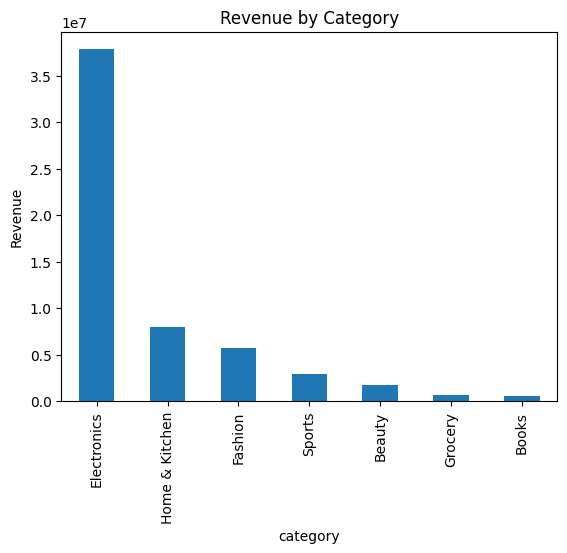

In [7]:
cat["sum"].plot(kind="bar")
plt.title("Revenue by Category"); plt.ylabel("Revenue"); plt.show()

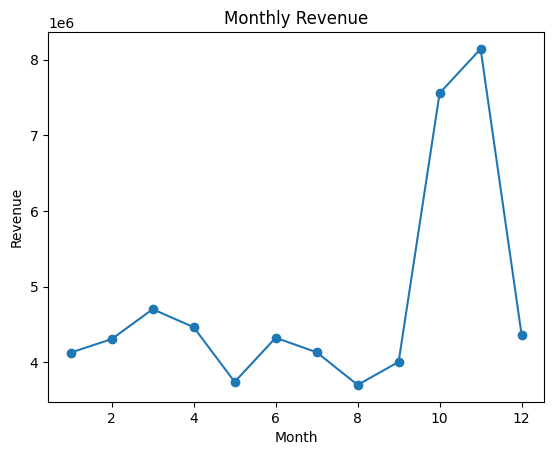

In [8]:
month["sum"].plot(kind="line", marker="o")
plt.title("Monthly Revenue"); plt.xlabel("Month"); plt.ylabel("Revenue"); plt.show()

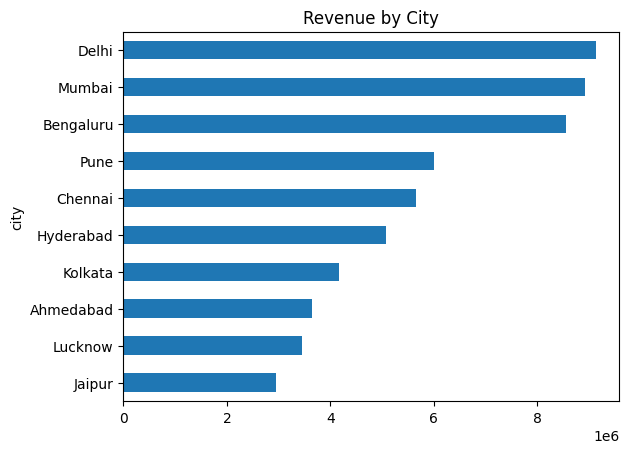

In [9]:
city["sum"].sort_values().plot(kind="barh")
plt.title("Revenue by City"); plt.show()

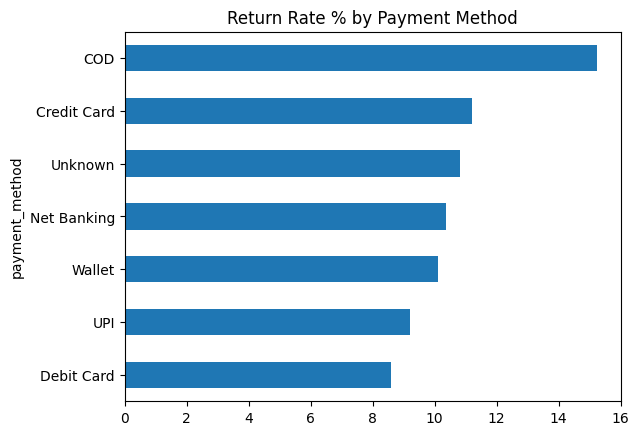

In [10]:
rate = df.groupby("payment_method")["is_returned"].mean() * 100
rate.sort_values().plot(kind="barh")
plt.title("Return Rate % by Payment Method"); plt.show()

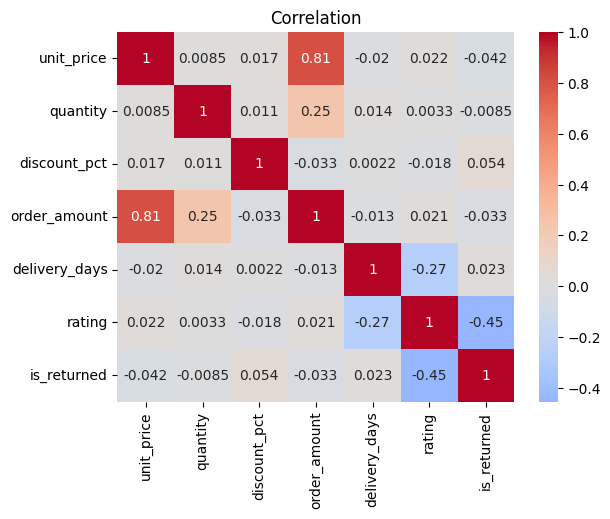

In [11]:
num = df[["unit_price", "quantity", "discount_pct", "order_amount", "delivery_days", "rating", "is_returned"]]
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation"); plt.show()

## 5. Insights

**Category:**  
*Electronics generates about 65.7% of total revenue (₹3.8 crore of ₹5.7 crore), even though it has fewer orders than others. The **Reason is price**: an average Electronics order is ₹20,660
versus ₹2,436 for Fashion. The business depends heavily on one category, so it should keep Electronics always in stock and also promote Home & Kitchen to reduce this dependence.*

**Month:**  
*Revenue almost doubles in **October** (₹75.6 lakh) and November (₹81.4 lakh) compared with a normal month (about ₹37-47 lakh), and orders rise from about 730 to over 1,250 per month. This is probably due to **festive-season shopping** (Diwali). The business should prepare stock and ads before October*

**City:**  
*Delhi (₹91 lakh), Mumbai (₹89 lakh) and Bengaluru (₹86 lakh) are the top three cities by revenue. Bengaluru has the most orders (1,607), but Delhi earns more, so Delhi customers spend more per order. The business should run premium offers in Delhi and volume-based offers in Bengaluru.*

